# 🛡️ Vendor Payment Guard
### A local AI agent that checks every vendor invoice *before* money leaves the company

**Course:** Agentic AI (STAI343) · **Built with:** LangGraph (state machine) + Ollama (local LLM, optional)

---

**The problem.** Fraudsters hack or copy a real supplier's email and send an invoice that looks genuine,
except the **bank account has been changed** to theirs. Indian companies have lost ₹2 crore (Chennai) and
₹2.35 crore (Pune) this way. Small accounts teams check invoices by hand, under time pressure.

**Our solution.** A security checkpoint for payments. Every invoice passes through a set of guards:

| Result | When |
|---|---|
| ✅ **APPROVE** | everything matches our records |
| 📞 **CALL THE VENDOR** | something is suspicious, so we phone the vendor on the number *we* have on file |
| ⛔ **BLOCK** | clearly dangerous, or the vendor denies sending it |
| ❌ **REJECT** | the invoice is incomplete and can't even be checked |

**Golden rule:** *the LLM reads, the rules decide.* The local LLM may help read a messy invoice,
but approve/block decisions are always made by fixed, auditable rules.

**Notebook map**
1. Settings (our finance policy)
2. Mock company data
3. Incoming test invoices
4. Tools: small functions the agent calls
5. State: the agent's memory
6. Nodes
7. Build the graph
8. Run the agent
9. Experiment: what if there's no reducer?
10. The loop, and how we stop infinite loops
11. Visual traceability: architecture, behaviour, delta trace
12. The local LLM in action

## 1. Settings: our "finance policy"

Everything the agent decides is based on these numbers. Change one, re-run, and the agent behaves differently.

- **`RISK_POINTS`**: each warning flag adds points to an invoice's risk score.
- **`APPROVE_BELOW` / `BLOCK_FROM`**: the score decides the route: approve, call the vendor, or block.
- **`MAX_CALLS`**: loop guard #1. We phone a vendor at most this many times, then stop.
- **`RUN_CONFIG`**: loop guard #2, a safety net. LangGraph itself stops a run that takes too many steps.

In [1]:
# ---- Settings: the finance policy of our agent ----

USE_LLM   = True                  # True  = local LLM (Ollama) reads the invoice text
LLM_MODEL = "qwen3:4b-instruct"   # False = simple Python parser reads it

MAX_CALLS = 3                     # loop guard #1 (business rule): phone the vendor at most 3 times
RUN_CONFIG = {"recursion_limit": 20}   # loop guard #2 (safety net): LangGraph stops any run after 20 steps

RISK_POINTS = {                   # how dangerous each warning flag is
    "DUPLICATE_INVOICE":    100,
    "BANK_DETAILS_CHANGED":  50,
    "NO_MATCHING_PO":        40,
    "AMOUNT_EXCEEDS_PO":     30,
    "GOODS_NOT_RECEIVED":    30,
    "INVALID_GSTIN":         40,
    "GSTIN_MISMATCH":        40,
}

APPROVE_BELOW = 30                # score  0-29 -> approve
BLOCK_FROM    = 80                # score 80+   -> block      (30-79 -> call the vendor)

## 2. Mock company data

Our pretend company is **Shakti Auto Components, Pune**. It buys raw material from 5 vendors.
In a real company this data lives in an accounting system (Tally, Zoho Books, SAP). Here it's plain Python dictionaries.

| Table | What it holds | Why the agent needs it |
|---|---|---|
| `VENDORS` | trusted vendor master: GSTIN, bank account, **phone on file** | to spot changed bank details and to know whom to call |
| `PURCHASE_ORDERS` | what we ordered and the agreed amount | an invoice must match a real order |
| `GOODS_RECEIPTS` | proof the goods arrived (GRN) | never pay for goods we didn't get |
| `PAID_INVOICES` | invoices already paid | to catch duplicates |
| `CALLBACK_SCRIPT` | what each vendor says when we phone them | simulated phone calls, so every run is the same |

> 🔑 **Key anti-fraud idea:** we always phone the number in **our** vendor master, never a number printed on the invoice.
> The fraudster controls the invoice. They don't control our records.

In [2]:
# ---- Trusted vendor master (our own records) ----
VENDORS = {
    "V001": {"name": "Sharma Steel Traders", "gstin": "27AABCS1234F1Z5",
             "bank_account": "50100234567", "phone": "+91-90000-10001"},
    "V002": {"name": "Patil Plastics",       "gstin": "27AACCP5678K1Z2",
             "bank_account": "31200456789", "phone": "+91-90000-10002"},
    "V003": {"name": "Gupta Bearings",       "gstin": "27AADFG9012L1Z8",
             "bank_account": "00912345678", "phone": "+91-90000-10003"},
    "V004": {"name": "Rao Rubber Works",     "gstin": "29AAEFR3456M1Z1",
             "bank_account": "20456789012", "phone": "+91-90000-10004"},
    "V005": {"name": "Mehta Packaging",      "gstin": "27AAGFM7890N1Z4",
             "bank_account": "60011223344", "phone": "+91-90000-10005"},
}

# ---- Purchase orders: what we ordered, and for how much (INR) ----
PURCHASE_ORDERS = {
    "PO-1001": {"vendor_id": "V001", "amount": 450000},
    "PO-1002": {"vendor_id": "V002", "amount": 120000},
    "PO-1003": {"vendor_id": "V003", "amount": 275000},
    "PO-1004": {"vendor_id": "V004", "amount":  98000},
    "PO-1005": {"vendor_id": "V005", "amount":  60000},
}

# ---- Goods receipts: which POs have actually been delivered ----
GOODS_RECEIPTS = {
    "PO-1001": "GRN-5001",
    "PO-1002": "GRN-5002",
    "PO-1003": "GRN-5003",
    "PO-1004": "GRN-5004",
    "PO-1005": "GRN-5005",
}

# ---- Invoices we have already paid: (vendor_id, invoice_no) ----
PAID_INVOICES = {
    ("V001", "SST/2026/0398"),
    ("V002", "PP/26/117"),
}

# ---- Simulated phone calls: what the vendor says on call 1, call 2, ... ----
# In real life a person phones the vendor. Here the answers are scripted
# so every run gives the same result (a deterministic demo).
CALLBACK_SCRIPT = {
    "+91-90000-10002": ["no_answer", "confirmed"],   # Patil: picks up on the 2nd call, confirms
    "+91-90000-10003": ["denied"],                   # Gupta: "We never changed our bank!" -> fraud
    "+91-90000-10004": [],                           # Rao: never picks up
}

print(f"Loaded {len(VENDORS)} vendors, {len(PURCHASE_ORDERS)} purchase orders, "
      f"{len(GOODS_RECEIPTS)} goods receipts, {len(PAID_INVOICES)} paid invoices.")

Loaded 5 vendors, 5 purchase orders, 5 goods receipts, 2 paid invoices.


## 3. Incoming test invoices

These 7 invoices are our test cases. Each one tests a different path through the agent.

| # | Invoice | What's special | Expected result |
|---|---|---|---|
| 1 | Sharma Steel | everything matches | ✅ APPROVE |
| 2 | Sharma Steel | already paid before (duplicate) | ⛔ BLOCK |
| 3 | Patil Plastics | new bank account, vendor confirms on the 2nd call | ✅ APPROVE after the loop |
| 4 | Gupta Bearings | new bank account, vendor says *"we never sent this"* | ⛔ BLOCK: **fraud caught** |
| 5 | Rao Rubber Works | new bank account, vendor never answers | ⛔ BLOCK after 3 calls (loop guard) |
| 6 | "Mehta Packaging" | fake GSTIN and a new bank account | ⛔ BLOCK |
| 7 | Mehta Packaging | PO number and amount missing | ❌ REJECT |

In [3]:
TEST_INVOICES = {
"1. Clean invoice": '''
TAX INVOICE
Invoice No: SST/2026/0412
Vendor: Sharma Steel Traders
PO Number: PO-1001
Amount: 450000
GSTIN: 27AABCS1234F1Z5
Bank Account: 50100234567
''',

"2. Duplicate invoice": '''
TAX INVOICE
Invoice No: SST/2026/0398
Vendor: Sharma Steel Traders
PO Number: PO-1001
Amount: 450000
GSTIN: 27AABCS1234F1Z5
Bank Account: 50100234567
''',

"3. Bank changed, vendor confirms": '''
TAX INVOICE
Invoice No: PP/26/131
Vendor: Patil Plastics
PO Number: PO-1002
Amount: 120000
GSTIN: 27AACCP5678K1Z2
Bank Account: 77889900112
''',

"4. Bank changed, vendor denies (fraud)": '''
TAX INVOICE
Invoice No: GB-2026-0077
Vendor: Gupta Bearings
PO Number: PO-1003
Amount: 275000
GSTIN: 27AADFG9012L1Z8
Bank Account: 66554433221
''',

"5. Bank changed, vendor never answers": '''
TAX INVOICE
Invoice No: RRW/0931
Vendor: Rao Rubber Works
PO Number: PO-1004
Amount: 98000
GSTIN: 29AAEFR3456M1Z1
Bank Account: 11223344556
''',

"6. Fake GSTIN + bank changed": '''
TAX INVOICE
Invoice No: MP/2026/552
Vendor: Mehta Packaging
PO Number: PO-1005
Amount: 60000
GSTIN: 27AAGFM78901Z4
Bank Account: 99887766554
''',

"7. Incomplete invoice": '''
TAX INVOICE
Invoice No: MP/2026/553
Vendor: Mehta Packaging
GSTIN: 27AAGFM7890N1Z4
Bank Account: 60011223344
''',
}

for name in TEST_INVOICES:
    print(name)

1. Clean invoice
2. Duplicate invoice
3. Bank changed, vendor confirms
4. Bank changed, vendor denies (fraud)
5. Bank changed, vendor never answers
6. Fake GSTIN + bank changed
7. Incomplete invoice


## 4. Tools: small functions the agent calls

A **tool** is a small function that does **one** job, usually *looking something up*.
The agent's nodes (next step) call these tools to make decisions. This is **function calling**:
the agent doesn't know the answers itself, so it calls the right function to find out.

| Tool | Question it answers |
|---|---|
| `find_vendor(name)` | Is this vendor in our master? What are their real details? |
| `find_purchase_order(po_number)` | Did we really order this? For how much? |
| `find_goods_receipt(po_number)` | Did the goods actually arrive? |
| `is_already_paid(vendor_id, invoice_no)` | Have we paid this invoice before? |
| `is_valid_gstin_format(gstin)` | Is the GSTIN a valid 15-character Indian GST number? |
| `call_vendor(phone, attempt)` | *(simulated)* What did the vendor say on this call? |

In [4]:
import re

def find_vendor(name):
    # Look up a vendor in our trusted master by name. Returns their record, or None if unknown.
    for vendor_id, vendor in VENDORS.items():
        if vendor["name"].lower() == name.strip().lower():
            return {"vendor_id": vendor_id, **vendor}
    return None

def find_purchase_order(po_number):
    # Return the purchase order, or None if we never placed it.
    return PURCHASE_ORDERS.get(po_number)

def find_goods_receipt(po_number):
    # Return the goods receipt number, or None if the goods never arrived.
    return GOODS_RECEIPTS.get(po_number)

def is_already_paid(vendor_id, invoice_no):
    # True if we have already paid this exact invoice.
    return (vendor_id, invoice_no) in PAID_INVOICES

# GSTIN = 2-digit state code + 10-char PAN + entity number + 'Z' + check character
GSTIN_PATTERN = r"[0-9]{2}[A-Z]{5}[0-9]{4}[A-Z][1-9A-Z]Z[0-9A-Z]"

def is_valid_gstin_format(gstin):
    # True if the GSTIN has the correct 15-character format.
    return re.fullmatch(GSTIN_PATTERN, gstin) is not None

def call_vendor(phone, attempt):
    # SIMULATED phone call. Returns "confirmed", "denied" or "no_answer".
    # 'attempt' is 1 for the first call, 2 for the second, and so on.
    answers = CALLBACK_SCRIPT.get(phone, [])
    if attempt <= len(answers):
        return answers[attempt - 1]
    return "no_answer"

### Quick test: do the tools work on their own?

Before building the agent, we test each tool by hand. If a tool is wrong, the agent will be wrong too.

In [5]:
print("find_vendor('Patil Plastics')       ->", find_vendor("Patil Plastics"))
print("find_vendor('Fake Traders Ltd')     ->", find_vendor("Fake Traders Ltd"))
print("find_purchase_order('PO-1003')      ->", find_purchase_order("PO-1003"))
print("find_purchase_order('PO-9999')      ->", find_purchase_order("PO-9999"))
print("find_goods_receipt('PO-1001')       ->", find_goods_receipt("PO-1001"))
print("is_already_paid('V001', 'SST/2026/0398') ->", is_already_paid("V001", "SST/2026/0398"))
print("is_already_paid('V001', 'SST/2026/0412') ->", is_already_paid("V001", "SST/2026/0412"))
print("is_valid_gstin_format('27AABCS1234F1Z5') ->", is_valid_gstin_format("27AABCS1234F1Z5"))
print("is_valid_gstin_format('27AAGFM78901Z4')  ->", is_valid_gstin_format("27AAGFM78901Z4"))

patil = VENDORS["V002"]["phone"]
rao   = VENDORS["V004"]["phone"]
print("call_vendor(Patil, attempt 1) ->", call_vendor(patil, 1))
print("call_vendor(Patil, attempt 2) ->", call_vendor(patil, 2))
print("call_vendor(Rao,   attempt 5) ->", call_vendor(rao, 5))

find_vendor('Patil Plastics')       -> {'vendor_id': 'V002', 'name': 'Patil Plastics', 'gstin': '27AACCP5678K1Z2', 'bank_account': '31200456789', 'phone': '+91-90000-10002'}
find_vendor('Fake Traders Ltd')     -> None
find_purchase_order('PO-1003')      -> {'vendor_id': 'V003', 'amount': 275000}
find_purchase_order('PO-9999')      -> None
find_goods_receipt('PO-1001')       -> GRN-5001
is_already_paid('V001', 'SST/2026/0398') -> True
is_already_paid('V001', 'SST/2026/0412') -> False
is_valid_gstin_format('27AABCS1234F1Z5') -> True
is_valid_gstin_format('27AAGFM78901Z4')  -> False
call_vendor(Patil, attempt 1) -> no_answer
call_vendor(Patil, attempt 2) -> confirmed
call_vendor(Rao,   attempt 5) -> no_answer


## 5. The State: the agent's memory

A normal chatbot is **stateless**: every message starts from zero.
Our agent is **stateful**: one dictionary called the **State** travels through every step,
and each step can read it and add to it.

Think of it as a **file folder that moves from desk to desk** in an accounts office.
Each desk (a **node**) reads the folder, does its one job, and adds a note.

Three words you must know:

| Word | Meaning | In our project |
|---|---|---|
| **State** | the shared folder | `PaymentState` below |
| **Delta** | the small change one node returns (*only* the keys it changed) | e.g. `{"errors": [], "audit_log": ["validate: ok"]}` |
| **Reducer** | the rule for *merging* a delta into the State | no reducer = **replace** the old value · `operator.add` = **append** to the old list |

Look at `risk_flags` and `audit_log` below: they use `Annotated[list, operator.add]`.
That means *"when a node returns this key, append it to the existing list instead of replacing it."*
We'll see why that matters in Step 3, when 4 checks write `risk_flags` **at the same time**.

In [6]:
import operator
from typing import TypedDict, Annotated

class PaymentState(TypedDict):
    raw_text: str          # the invoice text as received (the input)
    invoice: dict          # fields read from the text: invoice_no, vendor, po_number, amount, gstin, bank_account
    vendor: dict           # OUR trusted record of this vendor (from the vendor master)
    errors: list[str]      # reasons the invoice can't be checked at all (missing fields, unknown vendor)

    risk_flags: Annotated[list[str], operator.add]   # warnings from the checks      -> REDUCER: append
    risk_score: int        # total points of all risk flags
    call_attempts: int     # how many times we phoned the vendor (the LOOP COUNTER)
    vendor_response: str   # what the vendor said on the last call
    decision: str          # final answer: APPROVED / BLOCKED / REJECTED
    reason: str            # why we made that decision (for the accounts team)

    audit_log: Annotated[list[str], operator.add]    # one line per node, a full trail  -> REDUCER: append

## 6. Nodes: the desks the folder visits

A **node** is just a Python function:

```
def my_node(state):          # 1. receives the whole State
    ...do one job...
    return {"some_key": value}   # 2. returns ONLY what it changed (the delta)
```

LangGraph takes that delta and merges it into the State using the reducers.

### Node 1 · `read_invoice`: turn text into fields (parser + local LLM)

Invoices arrive as text. We read them in **two layers**:

1. **Simple parser (always runs first).** It reads lines like `Vendor: Patil Plastics`. It's instant and never makes mistakes,
   but it only understands our neat template.
2. **Local LLM (only if `USE_LLM = True` and the parser missed some fields).** Real invoices are often messy emails.
   We ask `qwen3:4b-instruct`, running in Ollama **on this laptop**, to read the text using **tool calling**.

**Why not just use the LLM for everything?** When we tested it on our 7 invoices, the LLM read almost everything right,
but it **copied two values wrongly**: it turned `PO-1001` into `PO-10_001`, and changed one digit of a bank account number.
In a payment system, one wrong digit can send money to the wrong account. So:

> 🔒 **Every value the LLM gives must appear word-for-word in the invoice text, or we throw it away.**
> The LLM *helps us read*; it never gets to *invent* data, and it never decides approve/block.

**How tool calling works here:**
1. We describe a tool, `submit_invoice_fields(...)`, as a normal Python function with a docstring. Ollama turns it into a schema the model understands.
2. The model reads the invoice and replies with a **tool call**: the function name plus the arguments it filled in.
3. Our code runs the function with those arguments, then **verifies** every value against the original text.
4. If Ollama isn't running, the node quietly falls back to the parser, so the agent still works offline.

In [7]:
import ollama

# ---- Layer 1: the simple parser ----
LABELS = {                       # which label on the invoice maps to which field
    "Invoice No":   "invoice_no",
    "Vendor":       "vendor",
    "PO Number":    "po_number",
    "Amount":       "amount",
    "GSTIN":        "gstin",
    "Bank Account": "bank_account",
}
REQUIRED_FIELDS = list(LABELS.values())

def parse_invoice_text(text):
    # Simple parser: reads "Label: value" lines from our invoice template.
    invoice = {}
    for line in text.splitlines():
        if ":" in line:
            label, value = line.split(":", 1)
            field = LABELS.get(label.strip())
            if field and value.strip():
                invoice[field] = value.strip()
    return invoice


# ---- Layer 2: the local LLM, using TOOL CALLING ----
def submit_invoice_fields(invoice_no: str = "", vendor: str = "", po_number: str = "",
                          amount: str = "", gstin: str = "", bank_account: str = "") -> dict:
    '''Submit the fields you read from the invoice. Use an empty string for any field that is not written on the invoice.

    Args:
        invoice_no: the invoice or bill number
        vendor: the supplier company name
        po_number: the purchase order (PO) number
        amount: the total amount payable in rupees
        gstin: the supplier's 15-character GSTIN
        bank_account: the bank account number the supplier wants to be paid into
    '''
    return {"invoice_no": invoice_no, "vendor": vendor, "po_number": po_number,
            "amount": amount, "gstin": gstin, "bank_account": bank_account}

LLM_INSTRUCTIONS = (
    "You read vendor invoices for an accounts team. Call the submit_invoice_fields tool exactly once, "
    "copying every value exactly as it is written on the invoice. Never guess or invent a value: "
    "if a field is not written on the invoice, pass an empty string."
)

def ask_llm_to_read(text):
    # Ask the local LLM to read the invoice. It answers by CALLING our tool.
    response = ollama.chat(
        model=LLM_MODEL,
        messages=[{"role": "system", "content": LLM_INSTRUCTIONS},
                  {"role": "user", "content": text}],
        tools=[submit_invoice_fields],          # the tool the model is allowed to call
        options={"temperature": 0},             # as repeatable as possible
    )
    for call in response.message.tool_calls or []:
        if call.function.name == "submit_invoice_fields":
            return submit_invoice_fields(**call.function.arguments)    # WE run the tool with ITS arguments
    return {}


def to_rupees(value):
    # "Rs. 4,50,000/-" -> 450000.  Returns None if there's no number.
    match = re.search(r"\d[\d,]*(\.\d+)?", str(value))
    return int(float(match.group().replace(",", ""))) if match else None


# ---- The node ----
def read_invoice(state):
    # NODE: read the raw text with the parser; let the local LLM fill only the gaps, and verify what it says.
    text = state["raw_text"]
    invoice = parse_invoice_text(text)
    how = "parser"

    missing = [field for field in REQUIRED_FIELDS if field not in invoice]
    if missing and USE_LLM:
        try:
            llm_fields = ask_llm_to_read(text)                                # TOOL CALL by the LLM
            for field in missing:
                value = str(llm_fields.get(field, "")).strip()
                if value and value in text:                                   # VERIFY: must be in the text
                    invoice[field] = value
            how = "parser + local LLM"
        except Exception as error:                                            # Ollama not running, etc.
            how = f"parser only (LLM unavailable: {type(error).__name__})"

    if "amount" in invoice:
        invoice["amount"] = to_rupees(invoice["amount"])

    found = sum(1 for field in REQUIRED_FIELDS if invoice.get(field))
    return {
        "invoice": invoice,
        "audit_log": [f"read_invoice [{how}]: found {found} of {len(REQUIRED_FIELDS)} fields"],
    }

### Node 2 · `validate`: can we even check this invoice?

Before any fraud check, the invoice must be **complete** and from a vendor **we know**.
If not, there's nothing to compare against, so later (Step 4) such invoices go straight to **REJECT**.

In [8]:
def validate(state):
    # NODE: make sure every required field is present and the vendor is in our master.
    invoice = state["invoice"]
    errors = [f"missing {field}" for field in REQUIRED_FIELDS if not invoice.get(field)]

    vendor = find_vendor(invoice.get("vendor", ""))          # TOOL CALL
    if invoice.get("vendor") and vendor is None:
        errors.append("vendor not in our master")

    note = "ok" if not errors else "; ".join(errors)
    return {
        "vendor": vendor or {},
        "errors": errors,
        "audit_log": [f"validate: {note}"],
    }

### Nodes 3–6 · the four fraud checks (they run **in parallel**)

Each check is one "guard" looking at one thing. They don't depend on each other,
so LangGraph runs all four **at the same time**.

| Check | Question | Flags it can raise |
|---|---|---|
| `check_duplicate` | Have we already paid this invoice? | `DUPLICATE_INVOICE` |
| `check_po_match` | Did we order this, for this amount, and did it arrive? | `NO_MATCHING_PO`, `AMOUNT_EXCEEDS_PO`, `GOODS_NOT_RECEIVED` |
| `check_bank_change` | Is the bank account the one in **our** records? | `BANK_DETAILS_CHANGED` |
| `check_gstin` | Is the GSTIN valid, and is it this vendor's GSTIN? | `INVALID_GSTIN`, `GSTIN_MISMATCH` |

Every check returns the **same two keys**: `risk_flags` (a list, maybe empty) and `audit_log`.
Four nodes writing `risk_flags` in the same step only works because of the **reducer** (see Section 9).

In [9]:
CHECKS = ["check_duplicate", "check_po_match", "check_bank_change", "check_gstin"]

def report(check_name, flags):
    # Helper: every check returns its flags plus one audit line.
    return {
        "risk_flags": flags,
        "audit_log": [f"{check_name}: {', '.join(flags) or 'clean'}"],
    }


def check_duplicate(state):
    # CHECK 1: have we already paid this exact invoice?
    invoice, vendor = state["invoice"], state["vendor"]
    flags = []
    if is_already_paid(vendor.get("vendor_id"), invoice.get("invoice_no")):    # TOOL CALL
        flags.append("DUPLICATE_INVOICE")
    return report("check_duplicate", flags)


def check_po_match(state):
    # CHECK 2: does the invoice match a real purchase order, and did the goods arrive?
    invoice, vendor = state["invoice"], state["vendor"]
    flags = []
    po = find_purchase_order(invoice.get("po_number"))                         # TOOL CALL
    if po is None or po["vendor_id"] != vendor.get("vendor_id"):
        flags.append("NO_MATCHING_PO")
    else:
        if invoice["amount"] > po["amount"]:
            flags.append("AMOUNT_EXCEEDS_PO")
        if find_goods_receipt(invoice["po_number"]) is None:                   # TOOL CALL
            flags.append("GOODS_NOT_RECEIVED")
    return report("check_po_match", flags)


def check_bank_change(state):
    # CHECK 3: is the invoice asking us to pay a DIFFERENT bank account than the one we trust?
    invoice, vendor = state["invoice"], state["vendor"]
    flags = []
    if invoice.get("bank_account") != vendor.get("bank_account"):
        flags.append("BANK_DETAILS_CHANGED")
    return report("check_bank_change", flags)


def check_gstin(state):
    # CHECK 4: is the GSTIN a valid format, and does it belong to this vendor?
    invoice, vendor = state["invoice"], state["vendor"]
    flags = []
    gstin = invoice.get("gstin", "")
    if not is_valid_gstin_format(gstin):                                        # TOOL CALL
        flags.append("INVALID_GSTIN")
    elif gstin != vendor.get("gstin"):
        flags.append("GSTIN_MISMATCH")
    return report("check_gstin", flags)

### Node 7 · `risk_scorer`: add up the points

This node runs **once**, after **all four** checks finish (a "join").
By then the reducer has merged every check's flags into one list, and the scorer just adds up their points from `RISK_POINTS`.

In [10]:
def risk_scorer(state):
    # NODE: turn the list of flags into one number using our finance policy.
    flags = state["risk_flags"]
    score = sum(RISK_POINTS[flag] for flag in flags)
    return {
        "risk_score": score,
        "audit_log": [f"risk_scorer: {', '.join(flags) or 'no flags'} -> score {score}"],
    }

### Node 8 · `callback_vendor`: phone the vendor

For medium-risk invoices we don't guess: we **ask the vendor**, on the phone number from **our own vendor master**.
A fraudster can put any number on a fake invoice, but they can't change our records.

The node also counts the call in `call_attempts`. In Step 5 this counter becomes the **loop guard**.

In [11]:
def callback_vendor(state):
    # NODE: phone the vendor on the number from OUR master (never the invoice) and ask: "Did you send this?"
    attempt = state.get("call_attempts", 0) + 1
    phone = state["vendor"]["phone"]
    answer = call_vendor(phone, attempt)                                        # TOOL CALL
    return {
        "call_attempts": attempt,
        "vendor_response": answer,
        "audit_log": [f"callback_vendor: call #{attempt} to {phone} -> {answer}"],
    }

### Nodes 9–11 · the three endings: `approve`, `block`, `reject`

Each ending writes the final `decision` and a human-readable `reason`, so the accounts team knows *why*.

In [12]:
def approve(state):
    # END NODE: safe to pay.
    if state.get("vendor_response") == "confirmed":
        reason = "vendor confirmed the invoice by phone"
    else:
        reason = f"low risk (score {state['risk_score']})"
    return {"decision": "APPROVED", "reason": reason, "audit_log": [f"approve: {reason}"]}


def block(state):
    # END NODE: do NOT pay. Send to the finance head for investigation.
    response = state.get("vendor_response")
    if response == "denied":
        reason = "vendor says they never sent this invoice - likely FRAUD"
    elif response == "no_answer":
        reason = f"could not reach vendor after {state['call_attempts']} call(s) - unverified"
    else:
        reason = f"risk score {state['risk_score']} is too high"
    return {"decision": "BLOCKED", "reason": reason, "audit_log": [f"block: {reason}"]}


def reject(state):
    # END NODE: the invoice can't even be checked, so send it back to the vendor.
    reason = "; ".join(state["errors"])
    return {"decision": "REJECTED", "reason": reason, "audit_log": [f"reject: {reason}"]}

### Routers: who goes where?

A **router** is a small function that looks at the State and returns **the name of the next node**.
It does **not** change the State; it only chooses a path. This is **conditional routing**.

| Router | Runs after | Possible next nodes |
|---|---|---|
| `route_after_validate` | `validate` | `reject`, or **all 4 checks** (returning a *list* starts them in parallel) |
| `route_by_score` | `risk_scorer` | `approve` (score < 30) · `callback_vendor` (30–79) · `block` (80+) |
| `route_after_call` | `callback_vendor` | `approve` if confirmed · **`callback_vendor` again** if no answer and calls < `MAX_CALLS` · otherwise `block` |

> `route_after_call` can send the invoice **back to the node it just came from**. That edge creates the **loop**.
> The `call_attempts < MAX_CALLS` test is what stops it running forever (see Section 10).

In [13]:
def route_after_validate(state):
    # ROUTER: incomplete invoices are rejected; complete ones go to all 4 checks in parallel.
    if state["errors"]:
        return "reject"
    return CHECKS


def route_by_score(state):
    # ROUTER: our finance policy turns the score into a path.
    score = state["risk_score"]
    if score < APPROVE_BELOW:
        return "approve"
    if score >= BLOCK_FROM:
        return "block"
    return "callback_vendor"


def route_after_call(state):
    # ROUTER: what did the vendor say?  (this is where the LOOP is decided)
    if state["vendor_response"] == "confirmed":
        return "approve"
    if state["vendor_response"] == "no_answer" and state["call_attempts"] < MAX_CALLS:
        return "callback_vendor"          # LOOP: try again
    return "block"                        # denied, or we've used up all our calls

## 7. Build the graph

Building a LangGraph agent always has the same 4 moves:

1. `StateGraph(PaymentState)`: create a graph that carries our State
2. `add_node(name, function)`: register each desk
3. `add_edge(a, b)`: draw the arrows (`START` = entry, `END` = exit)
4. `compile()`: turn the blueprint into a runnable agent

**How this graph grows, step by step:**

| Version | Added | Shape |
|---|---|---|
| v1 (Step 2) | `read_invoice`, `validate` | straight line |
| v2 (Step 3) | 4 checks + `risk_scorer` | **fan-out** (1 → 4 in parallel) and **join** (4 → 1) |
| v3 (Step 4) | `callback_vendor`, `approve`, `block`, `reject` + 3 routers | **conditional edges** (branches) |
| **v4 (Step 5)** | edge `callback_vendor → callback_vendor` | a **cycle** (the retry loop) |

- **Fan-out:** `route_after_validate` returns the *list* `CHECKS`, so all four checks start in the same step.
- **Conditional edge:** `add_conditional_edges(node, router, possible_next_nodes)`: after `node` runs, call `router` to pick the path.
- **Cycle:** `callback_vendor` can route back to itself. A graph with a cycle is what makes this an *agent loop*, not just a pipeline.
- **Join:** `add_edge(CHECKS, "risk_scorer")` with a *list* means "wait until **all** of these are done, then run the scorer once".

In [14]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(PaymentState)

# --- nodes ---
builder.add_node("read_invoice", read_invoice)
builder.add_node("validate", validate)
builder.add_node("check_duplicate", check_duplicate)
builder.add_node("check_po_match", check_po_match)
builder.add_node("check_bank_change", check_bank_change)
builder.add_node("check_gstin", check_gstin)
builder.add_node("risk_scorer", risk_scorer)
builder.add_node("callback_vendor", callback_vendor)
builder.add_node("approve", approve)
builder.add_node("block", block)
builder.add_node("reject", reject)

# --- edges ---
builder.add_edge(START, "read_invoice")
builder.add_edge("read_invoice", "validate")
builder.add_conditional_edges("validate", route_after_validate, ["reject"] + CHECKS)   # reject OR fan-out
builder.add_edge(CHECKS, "risk_scorer")                                                # join
builder.add_conditional_edges("risk_scorer", route_by_score, ["approve", "callback_vendor", "block"])
builder.add_conditional_edges("callback_vendor", route_after_call, ["approve", "callback_vendor", "block"])   # LOOP
for ending in ["approve", "block", "reject"]:
    builder.add_edge(ending, END)

graph = builder.compile()

# Draw the structure locally (no internet). The ASCII drawer can't draw an edge from a node
# back to itself, so we leave the loop edge out of the picture and print it underneath.
structure = graph.get_graph()
structure.edges = [edge for edge in structure.edges if edge.source != edge.target]
print(structure.draw_ascii())
print("+ LOOP edge (not drawn above): callback_vendor -> callback_vendor")

                                                         +-----------+                                                     
                                                         | __start__ |                                                     
                                                         +-----------+                                                     
                                                                *                                                          
                                                                *                                                          
                                                                *                                                          
                                                        +--------------+                                                   
                                                        | read_invoice |                                                   
        

## 8. Run the agent

### Watch the deltas for one invoice
`graph.stream(..., stream_mode="updates")` shows **what each node returned** (its delta), one node at a time.
This is the core skill for **tracing the delta**.

We use invoice 4 (Gupta Bearings, bank account changed). Follow it: four parallel checks → score 50 →
the router sends it to `callback_vendor` → the vendor says **"denied"** → the router sends it to `block`. **Fraud caught.**

In [15]:
invoice_text = TEST_INVOICES["4. Bank changed, vendor denies (fraud)"]

for update in graph.stream({"raw_text": invoice_text}, stream_mode="updates", config=RUN_CONFIG):
    for node_name, delta in update.items():
        tag = "  (parallel)" if node_name in CHECKS else ""
        print(f"node '{node_name}'{tag} returned:")
        for key, value in delta.items():
            print(f"      {key}: {value}")
        print()

node 'read_invoice' returned:
      invoice: {'invoice_no': 'GB-2026-0077', 'vendor': 'Gupta Bearings', 'po_number': 'PO-1003', 'amount': 275000, 'gstin': '27AADFG9012L1Z8', 'bank_account': '66554433221'}
      audit_log: ['read_invoice [parser]: found 6 of 6 fields']

node 'validate' returned:
      vendor: {'vendor_id': 'V003', 'name': 'Gupta Bearings', 'gstin': '27AADFG9012L1Z8', 'bank_account': '00912345678', 'phone': '+91-90000-10003'}
      errors: []
      audit_log: ['validate: ok']

node 'check_bank_change'  (parallel) returned:
      risk_flags: ['BANK_DETAILS_CHANGED']
      audit_log: ['check_bank_change: BANK_DETAILS_CHANGED']

node 'check_duplicate'  (parallel) returned:
      risk_flags: []
      audit_log: ['check_duplicate: clean']

node 'check_gstin'  (parallel) returned:
      risk_flags: []
      audit_log: ['check_gstin: clean']

node 'check_po_match'  (parallel) returned:
      risk_flags: []
      audit_log: ['check_po_match: clean']

node 'risk_scorer' returned:

### Run all 7 invoices and compare with what we expect

`graph.invoke(...)` runs the whole graph and returns the **final State**.
`EXPECTED` is our **test sheet**: the decision each invoice *should* get. The last column checks the agent against it.

> In Step 4 invoice 3 showed ❌: Patil missed the first call and we gave up immediately.
> With the retry loop (Step 5) it's now ✅. All 7 should pass.

In [16]:
import pandas as pd

EXPECTED = {
    "1. Clean invoice":                       "APPROVED",
    "2. Duplicate invoice":                   "BLOCKED",
    "3. Bank changed, vendor confirms":       "APPROVED",
    "4. Bank changed, vendor denies (fraud)": "BLOCKED",
    "5. Bank changed, vendor never answers":  "BLOCKED",
    "6. Fake GSTIN + bank changed":           "BLOCKED",
    "7. Incomplete invoice":                  "REJECTED",
}

rows = []
for name, text in TEST_INVOICES.items():
    final_state = graph.invoke({"raw_text": text}, config=RUN_CONFIG)
    rows.append({
        "invoice": name,
        "risk_flags": ", ".join(final_state.get("risk_flags", [])) or "-",
        "score": final_state.get("risk_score", "-"),
        "calls": final_state.get("call_attempts", 0),
        "decision": final_state["decision"],
        "reason": final_state["reason"],
        "as expected?": "✅" if final_state["decision"] == EXPECTED[name] else "❌",
    })

summary = pd.DataFrame(rows)
summary

,invoice,risk_flags,score,calls,decision,reason,as expected?
0,1. Clean invoice,-,0,0,APPROVED,low risk (score 0),✅
1,2. Duplicate invoice,DUPLICATE_INVOICE,100,0,BLOCKED,risk score 100 is too high,✅
2,"3. Bank changed, vendor confirms",BANK_DETAILS_CHANGED,50,2,APPROVED,vendor confirmed the invoice by phone,✅
3,"4. Bank changed, vendor denies (fraud)",BANK_DETAILS_CHANGED,50,1,BLOCKED,vendor says they never sent this invoice - lik...,✅
4,"5. Bank changed, vendor never answers",BANK_DETAILS_CHANGED,50,3,BLOCKED,could not reach vendor after 3 call(s) - unver...,✅
5,6. Fake GSTIN + bank changed,"BANK_DETAILS_CHANGED, INVALID_GSTIN",90,0,BLOCKED,risk score 90 is too high,✅
6,7. Incomplete invoice,-,-,0,REJECTED,missing po_number; missing amount,✅


## 9. Experiment: what if `risk_flags` had **no reducer**?

This is the most important idea in the project, so let's prove it rather than just say it.

The four checks finish in the **same step**, and each returns a `risk_flags` value.
- **With** `Annotated[list, operator.add]`, LangGraph *appends* them: `[] + [] + ["BANK_DETAILS_CHANGED"] + ["INVALID_GSTIN"]`.
- **Without** a reducer, LangGraph would have to *replace* the value, but with which of the four? It can't choose,
  so it stops with an `InvalidUpdateError`.

Below we build a tiny copy of the graph whose state has a **plain** `risk_flags: list[str]`, and run it.

In [17]:
class StateWithoutReducer(TypedDict):
    invoice: dict
    vendor: dict
    risk_flags: list[str]                             # <-- NO reducer here
    audit_log: Annotated[list[str], operator.add]

test = StateGraph(StateWithoutReducer)
for check in CHECKS:
    test.add_node(check, globals()[check])            # reuse our real check functions
    test.add_edge(START, check)
    test.add_edge(check, END)
broken_graph = test.compile()

parsed = parse_invoice_text(TEST_INVOICES["6. Fake GSTIN + bank changed"])
try:
    broken_graph.invoke({"invoice": parsed, "vendor": find_vendor(parsed["vendor"])})
except Exception as error:
    print("❌", type(error).__name__)
    print(str(error).splitlines()[0])

❌ TypeError
'>' not supported between instances of 'str' and 'int'


**What we learn:** parallel nodes writing to the same key **need a reducer**.
The reducer is the rule that says how to combine their deltas. Here the rule is "join the lists".

## 10. The loop, and how we stop infinite loops

### The loop
Real vendors don't always pick up. So instead of giving up, the agent **calls again**:

```
                ┌──────────── no answer & calls < MAX_CALLS ────────────┐
                ▼                                                        │
risk_scorer ─► callback_vendor ──► route_after_call ─────────────────────┘
                                        │
                                        ├── confirmed ──────────────► approve
                                        ├── denied ─────────────────► block   (fraud!)
                                        └── no answer & calls = 3 ──► block   (unverified)
```

Each trip around the loop, `callback_vendor` returns a **delta** with `call_attempts` one higher.
The router reads that number every time. This is how State lets a loop **remember** what already happened.

### Watch the loop run
- **Invoice 3 (Patil):** misses call 1, confirms on call 2 → the loop **ends naturally** → APPROVED.
- **Invoice 5 (Rao):** never answers → the loop is **stopped by our guard** after 3 calls → BLOCKED.

In [18]:
for name in ["3. Bank changed, vendor confirms", "5. Bank changed, vendor never answers"]:
    final_state = graph.invoke({"raw_text": TEST_INVOICES[name]}, config=RUN_CONFIG)
    print(f"=== {name} ===")
    for line in final_state["audit_log"]:
        if line.startswith(("callback_vendor", "approve", "block")):
            print("  ", line)
    print(f"   -> {final_state['decision']} after {final_state['call_attempts']} call(s)\n")

=== 3. Bank changed, vendor confirms ===
   callback_vendor: call #1 to +91-90000-10002 -> no_answer
   callback_vendor: call #2 to +91-90000-10002 -> confirmed
   approve: vendor confirmed the invoice by phone
   -> APPROVED after 2 call(s)

=== 5. Bank changed, vendor never answers ===
   callback_vendor: call #1 to +91-90000-10004 -> no_answer
   callback_vendor: call #2 to +91-90000-10004 -> no_answer
   callback_vendor: call #3 to +91-90000-10004 -> no_answer
   block: could not reach vendor after 3 call(s) - unverified
   -> BLOCKED after 3 call(s)



### Two guards against an infinite loop

| Guard | Where | What it does |
|---|---|---|
| **#1 Business rule** | `route_after_call`: `call_attempts < MAX_CALLS` | After 3 calls, stop and block. This is the *intended* way the loop ends. |
| **#2 Safety net** | `RUN_CONFIG = {"recursion_limit": 20}` | LangGraph counts **steps** (supersteps). If a run goes past the limit, it raises `GraphRecursionError` instead of running forever. This catches *bugs*. |

A normal run needs at most 8 steps: `read_invoice → validate → 4 checks (1 step, parallel) → risk_scorer → call → call → call → block`.
So 20 is plenty for real runs, but still catches a runaway loop.

### Experiment: remove guard #1 and see what happens
Below is a tiny graph with only `callback_vendor` and a **broken router that forgets to count calls**.
Rao never answers, so without guard #1 it would call forever. Guard #2 stops it.
(We use a small limit of 6 here just to keep the output short.)

In [19]:
from langgraph.errors import GraphRecursionError

def route_after_call_NO_GUARD(state):
    # BROKEN ROUTER: no MAX_CALLS check, so "no answer" always means "call again".
    if state["vendor_response"] == "no_answer":
        return "callback_vendor"
    return END

loop_test = StateGraph(PaymentState)
loop_test.add_node("callback_vendor", callback_vendor)            # our real node
loop_test.add_edge(START, "callback_vendor")
loop_test.add_conditional_edges("callback_vendor", route_after_call_NO_GUARD, ["callback_vendor", END])
runaway_graph = loop_test.compile()

rao = {"vendor_id": "V004", **VENDORS["V004"]}                    # Rao never picks up
try:
    for update in runaway_graph.stream({"vendor": rao}, stream_mode="updates", config={"recursion_limit": 6}):
        print(update["callback_vendor"]["audit_log"][0])
except GraphRecursionError as error:
    print("\n🛑 GraphRecursionError:", str(error).splitlines()[0])

callback_vendor: call #1 to +91-90000-10004 -> no_answer
callback_vendor: call #2 to +91-90000-10004 -> no_answer
callback_vendor: call #3 to +91-90000-10004 -> no_answer
callback_vendor: call #4 to +91-90000-10004 -> no_answer
callback_vendor: call #5 to +91-90000-10004 -> no_answer
callback_vendor: call #6 to +91-90000-10004 -> no_answer

🛑 GraphRecursionError: Recursion limit of 6 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.


**What we learn:**
- A cycle in a graph is powerful (retry, re-check, ask again), but it **must** have an exit condition stored in the State.
- Guard #1 (`MAX_CALLS`) is business logic. Guard #2 (`recursion_limit`) is a seatbelt for bugs. A good agent has both.

## 11. Visual traceability: seeing what the agent did

Text logs are hard to read. Here the code **draws** the agent:

1. **The architecture**: every node and edge, including the loop.
2. **The behaviour**: the same graph drawn 7 times, with the path each invoice actually took highlighted.
3. **The delta trace**: a step-by-step table of what each node returned.

Everything is drawn with `matplotlib` + `networkx` on your own machine, so no internet is needed.
The edges come straight from `graph.get_graph()`, so the picture always matches the real code.

### Helper functions
- `trace(name)`: runs one invoice with `stream_mode="updates"` and records every `(node, delta)` in order.
- `path_taken(steps)`: works out which nodes were visited and which edges were used.
  The 4 parallel checks count as one "stage", so `validate` connects to all four and all four connect to `risk_scorer`.
- `draw_agent(...)`: draws the graph, colouring the visited nodes and edges.

In [20]:
import os
import matplotlib.pyplot as plt
import networkx as nx

# Where each node sits in the picture (x, y). Fixed, so every drawing has the same layout.
POSITIONS = {
    "__start__":         (0, 12),
    "read_invoice":      (0, 10.8),
    "validate":          (0, 9.6),
    "check_duplicate":   (-5, 8),
    "check_po_match":    (-1.7, 8),
    "check_bank_change": (1.7, 8),
    "check_gstin":       (5, 8),
    "reject":            (8.5, 9),
    "risk_scorer":       (0, 6.4),
    "callback_vendor":   (0, 4.8),
    "approve":           (-4.5, 3.2),
    "block":             (4.5, 3.2),
    "__end__":           (0, 1.6),
}
NODE_LABELS = {node: node.strip("_").replace("_", "\n") for node in POSITIONS}
DECISION_COLOURS = {"APPROVED": "#2e7d32", "BLOCKED": "#c62828", "REJECTED": "#ef6c00"}
GRAPH_EDGES = [(edge.source, edge.target) for edge in graph.get_graph().edges]
LOOP_EDGE = ("callback_vendor", "callback_vendor")


def trace(invoice_name):
    # Run one invoice and record every node's delta, in the order they happened.
    steps = []
    stream = graph.stream({"raw_text": TEST_INVOICES[invoice_name]}, stream_mode="updates", config=RUN_CONFIG)
    for update in stream:
        for node, delta in update.items():
            steps.append((node, delta))
    return steps


def path_taken(steps):
    # Group visited nodes into stages (the 4 parallel checks are one stage), then link each stage to the next.
    stages = [["__start__"]]
    for node, _ in steps:
        if node in CHECKS and stages[-1][0] in CHECKS:
            stages[-1].append(node)
        else:
            stages.append([node])
    stages.append(["__end__"])
    visited = {node for stage in stages for node in stage}
    used_edges = {(a, b) for here, after in zip(stages, stages[1:])
                  for a in here for b in after if (a, b) in GRAPH_EDGES}
    return visited, used_edges


def draw_agent(ax, visited=None, used_edges=(), colour="#1565c0", title="", node_size=1500, font_size=6.5):
    # Draw the graph. Visited nodes/edges are coloured; everything else is grey.
    g = nx.DiGraph()
    g.add_nodes_from(POSITIONS)
    g.add_edges_from(e for e in GRAPH_EDGES if e != LOOP_EDGE)     # the loop is drawn separately below
    visited = set(POSITIONS) if visited is None else visited

    nx.draw_networkx_nodes(g, POSITIONS, ax=ax, node_size=node_size,
                           node_color=[colour if n in visited else "#e0e0e0" for n in g.nodes])
    grey_edges = [e for e in g.edges if e not in used_edges]
    coloured_edges = [e for e in g.edges if e in used_edges]
    nx.draw_networkx_edges(g, POSITIONS, ax=ax, edgelist=grey_edges, edge_color="#b0b0b0",
                           node_size=node_size, arrowsize=8)
    nx.draw_networkx_edges(g, POSITIONS, ax=ax, edgelist=coloured_edges, edge_color=colour,
                           width=2.5, node_size=node_size, arrowsize=12)
    nx.draw_networkx_labels(g, POSITIONS, ax=ax, font_size=font_size, font_color="white",
                            labels={n: NODE_LABELS[n] for n in g.nodes if n in visited})
    nx.draw_networkx_labels(g, POSITIONS, ax=ax, font_size=font_size, font_color="#555555",
                            labels={n: NODE_LABELS[n] for n in g.nodes if n not in visited})

    # The retry LOOP: an arrow that leaves callback_vendor and comes back to it.
    loop_used = LOOP_EDGE in used_edges
    loop_colour = colour if loop_used else "#b0b0b0"
    x, y = POSITIONS["callback_vendor"]
    ax.annotate("", xy=(x + 0.6, y - 0.3), xytext=(x + 0.6, y + 0.3),
                arrowprops=dict(arrowstyle="-|>", color=loop_colour, lw=2.5 if loop_used else 1.2,
                                connectionstyle="arc3,rad=-1.8"))
    ax.text(x + 1.55, y, "retry\nloop", fontsize=font_size + 1, color=loop_colour, va="center",
            fontweight="bold" if loop_used else "normal")

    ax.set_xlim(-6.2, 9.6)
    ax.set_ylim(0.8, 12.8)
    ax.set_title(title, fontsize=10)
    ax.axis("off")


os.makedirs("assets", exist_ok=True)   # pictures are also saved here for the README and tutorial

### 11.1 The architecture
Every node and edge of the compiled graph. Look for the **retry loop** arrow on `callback_vendor`: that's the cycle that makes this an agent, not just a pipeline.

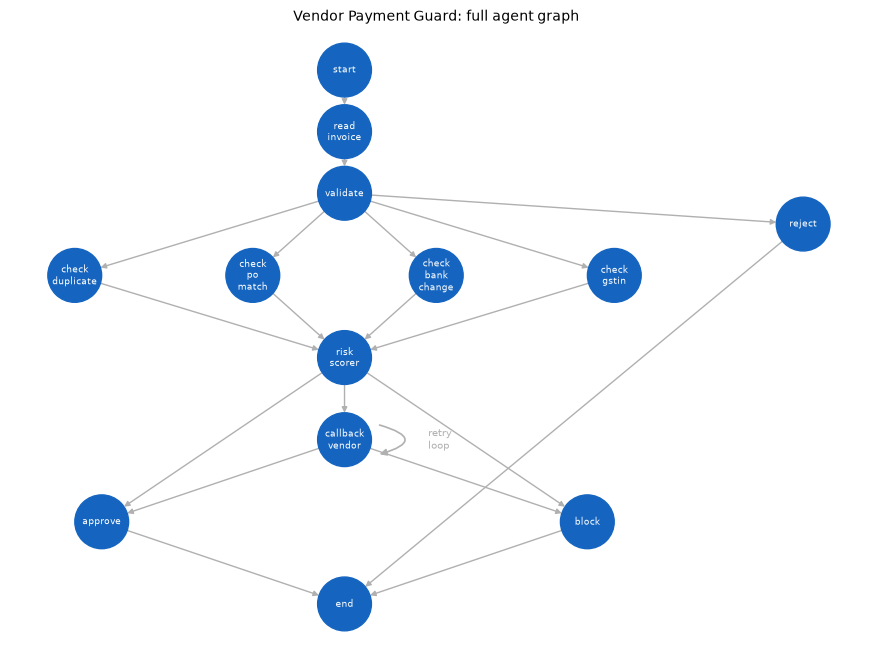

In [21]:
fig, ax = plt.subplots(figsize=(11, 8))
draw_agent(ax, title="Vendor Payment Guard: full agent graph")
fig.savefig("assets/architecture.png", dpi=150, bbox_inches="tight")
plt.show()

### 11.2 The behaviour: one graph, seven different paths
Each picture is the **same agent**. The coloured path is the route one invoice actually took.
Green = approved, red = blocked, orange = rejected.

Notice:
- **Invoice 1** goes straight from the scorer to `approve`.
- **Invoices 3, 4, 5** pass through `callback_vendor`. Invoices 3 and 5 also use the **loop**.
- **Invoices 2 and 6** score 80+ and skip the call entirely.
- **Invoice 7** never reaches the checks; it's rejected at `validate`.

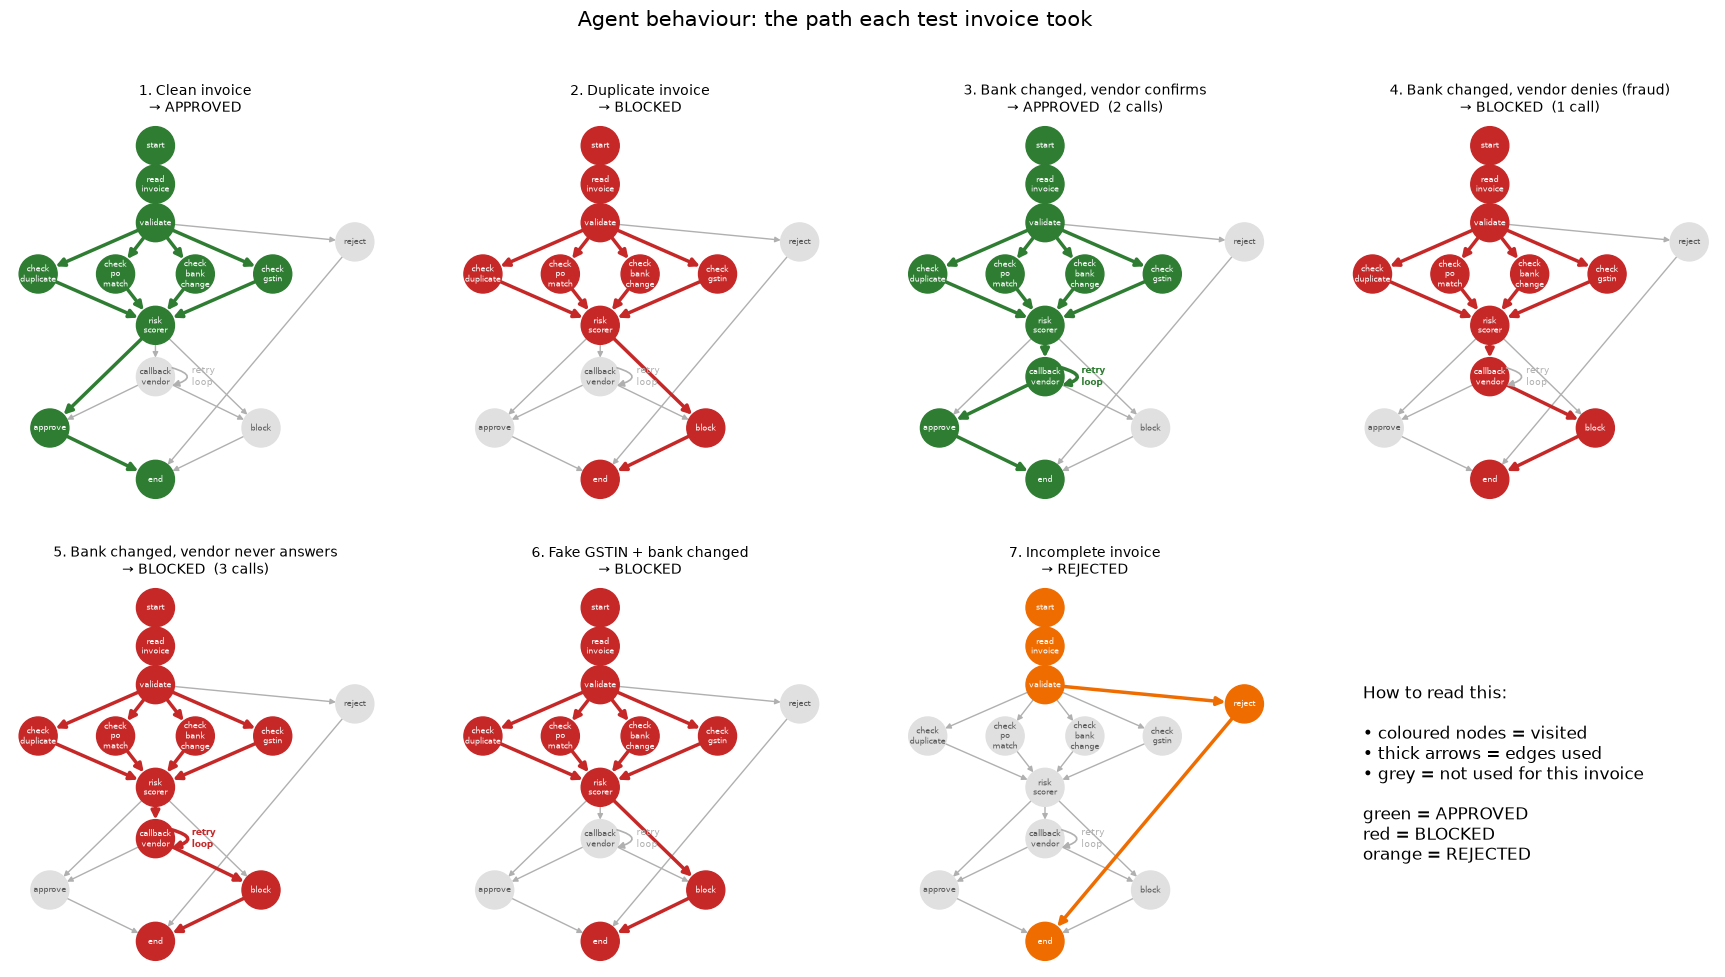

In [22]:
fig, axes = plt.subplots(2, 4, figsize=(22, 11))

for ax, name in zip(axes.flat, TEST_INVOICES):
    steps = trace(name)
    decision = steps[-1][1]["decision"]
    calls = sum(1 for node, _ in steps if node == "callback_vendor")
    visited, used_edges = path_taken(steps)
    subtitle = f"{name}\n→ {decision}" + (f"  ({calls} call{'s' if calls > 1 else ''})" if calls else "")
    draw_agent(ax, visited, used_edges, DECISION_COLOURS[decision], subtitle, node_size=750, font_size=5.5)

axes.flat[-1].axis("off")
axes.flat[-1].text(0.05, 0.5,
    "How to read this:\n\n"
    "• coloured nodes = visited\n"
    "• thick arrows = edges used\n"
    "• grey = not used for this invoice\n\n"
    "green = APPROVED\nred = BLOCKED\norange = REJECTED",
    fontsize=12, va="center")
fig.suptitle("Agent behaviour: the path each test invoice took", fontsize=15)
fig.savefig("assets/behaviour_paths.png", dpi=120, bbox_inches="tight")
plt.show()

### 11.3 Tracing the delta: invoice 5, step by step

This table is the agent's **flight recorder**. Each row is one node, and the middle column is the **delta**: the
*only* keys that node changed. (The `audit_log` line is shown separately on the right.)

How to read it:
- Rows 3–6 are the **parallel checks**. Each returns its own `risk_flags`; the reducer merges them before `risk_scorer` (row 7) runs.
- Rows 8–10 are the **loop**: `call_attempts` goes 1 → 2 → 3. When it reaches `MAX_CALLS`, the router sends the invoice to `block`.

In [23]:
pd.set_option("display.max_colwidth", 90)

def delta_table(steps):
    # One row per node: what it changed (the delta) and the note it wrote to the audit log.
    rows = []
    for number, (node, delta) in enumerate(steps, start=1):
        changes = {key: value for key, value in delta.items() if key != "audit_log"}
        rows.append({"#": number, "node": node, "delta (what changed)": changes,
                     "audit note": delta["audit_log"][0]})
    return pd.DataFrame(rows).set_index("#")

delta_table(trace("5. Bank changed, vendor never answers"))

,node,delta (what changed),audit note
#,,,
1,read_invoice,"{'invoice': {'invoice_no': 'RRW/0931', 'vendor': 'Rao Rubber Works', 'po_number': 'PO-...",read_invoice [parser]: found 6 of 6 fields
2,validate,"{'vendor': {'vendor_id': 'V004', 'name': 'Rao Rubber Works', 'gstin': '29AAEFR3456M1Z1...",validate: ok
3,check_bank_change,{'risk_flags': ['BANK_DETAILS_CHANGED']},check_bank_change: BANK_DETAILS_CHANGED
4,check_duplicate,{'risk_flags': []},check_duplicate: clean
5,check_gstin,{'risk_flags': []},check_gstin: clean
6,check_po_match,{'risk_flags': []},check_po_match: clean
7,risk_scorer,{'risk_score': 50},risk_scorer: BANK_DETAILS_CHANGED -> score 50
8,callback_vendor,"{'call_attempts': 1, 'vendor_response': 'no_answer'}",callback_vendor: call #1 to +91-90000-10004 -> no_answer
9,callback_vendor,"{'call_attempts': 2, 'vendor_response': 'no_answer'}",callback_vendor: call #2 to +91-90000-10004 -> no_answer


## 12. The local LLM in action

### 12.1 A messy, real-world invoice
Real vendors don't use our neat template. Here's an invoice written as a normal email.
The simple parser finds **nothing** in it. Let's run the **same agent** twice: once with `USE_LLM = False`, once with `True`.

In [24]:
MESSY_EMAIL = '''Hi Accounts team,
Please find our bill no. SST/2026/0415 for the 12 MS steel coils delivered last week against your order PO-1001.
Total payable: Rs. 4,50,000/- (inclusive of GST). Our GSTIN is 27AABCS1234F1Z5.
Kindly remit the payment to our HDFC current a/c no. 50100234567.
Regards,
Accounts, Sharma Steel Traders'''

for setting in [False, True]:
    USE_LLM = setting
    result = graph.invoke({"raw_text": MESSY_EMAIL}, config=RUN_CONFIG)
    print(f"USE_LLM = {setting}")
    print("   ", result["audit_log"][0])
    print("    fields:", result["invoice"])
    print(f"    -> {result['decision']}: {result['reason']}\n")

USE_LLM = True     # back to the default from Settings

USE_LLM = False
    read_invoice [parser]: found 0 of 6 fields
    fields: {}
    -> REJECTED: missing invoice_no; missing vendor; missing po_number; missing amount; missing gstin; missing bank_account



USE_LLM = True
    read_invoice [parser + local LLM]: found 6 of 6 fields
    fields: {'invoice_no': 'SST/2026/0415', 'vendor': 'Sharma Steel Traders', 'po_number': 'PO-1001', 'amount': 450000, 'gstin': '27AABCS1234F1Z5', 'bank_account': '50100234567'}
    -> APPROVED: low risk (score 0)



With the parser alone, the email is **rejected** (no fields found). With the local LLM, the agent reads it,
every value passes the "must appear in the text" check, and the normal fraud checks then **approve** it.
**Same graph, same rules; only the reading got smarter.**

### 12.2 How much can we trust the LLM? (an honest test)
Our 7 test invoices use the neat template, so the parser's reading is the **ground truth**.
Below we ask the LLM to read each one *by itself* and compare, field by field.
Any ❌ is a value the LLM copied wrongly, which our "must appear in the text" rule would catch and throw away.

*(This makes 7 calls to the local model, so it takes a little while. Results may differ slightly on other machines.)*

In [25]:
rows = []
for name, text in TEST_INVOICES.items():
    truth = parse_invoice_text(text)
    llm = ask_llm_to_read(text)
    wrong = [f"{field}: '{llm.get(field)}' (real: '{truth.get(field, '')}')"
             for field in REQUIRED_FIELDS if str(llm.get(field, "")).strip() != truth.get(field, "")]
    rows.append({"invoice": name,
                 "fields read correctly": f"{len(REQUIRED_FIELDS) - len(wrong)} / {len(REQUIRED_FIELDS)}",
                 "LLM mistakes": "; ".join(wrong) or "none ✅"})

pd.DataFrame(rows)

,invoice,fields read correctly,LLM mistakes
0,1. Clean invoice,5 / 6,po_number: 'PO-10_001' (real: 'PO-1001')
1,2. Duplicate invoice,5 / 6,po_number: 'PO-10_001' (real: 'PO-1001')
2,"3. Bank changed, vendor confirms",5 / 6,po_number: 'PO-10_02' (real: 'PO-1002')
3,"4. Bank changed, vendor denies (fraud)",6 / 6,none ✅
4,"5. Bank changed, vendor never answers",6 / 6,none ✅
5,6. Fake GSTIN + bank changed,5 / 6,po_number: 'PO-10 05' (real: 'PO-1005')
6,7. Incomplete invoice,6 / 6,none ✅


**What we learn:**
- A small local LLM is great at *understanding* messy text, but it can still *copy* a value wrongly.
- Small wording changes matter: when the tool description gave `PO-1001` as an *example*, the model kept copying
  the PO number as `PO-10_01`. Our verification rule refused it (it's not in the text), so no harm was done.
  Removing the example fixed the email, but the table above shows the model can *still* garble numbers like `PO-1002`.
  **This is exactly why we never trust LLM output without checking it.**
- So we use it as a **helper with a safety check**: parser first, LLM only for the gaps, every LLM value verified against the source text.
- And the LLM never makes the money decision. **The LLM reads, the rules decide.**

---
✅ **Step 7 done:** `read_invoice` uses the local LLM (Ollama, tool calling) to read messy invoices, verifies every value,
and falls back to the parser if Ollama is off. The core agent is complete.

**Next (Step 8):** the README (with flow diagrams) and the beginner tutorial.